# Capitolo 15 — Rendering, footprint e riproiezione in 3D

Arcangelo Distante e Cosimo Distante · **Computer Vision**

Densità, colori, Gaussiane e camere sono assegnati. Non si addestra NeRF, non si usa un rasterizzatore 3DGS completo e non si esegue VGGT. Gli esperimenti verificano integrazione discreta, linearizzazione e gauge.

## Avvio in Google Colab o in locale

Aprire questo file in Colab e selezionare un runtime Python su CPU; non è richiesta una GPU. Usare **Esegui tutto** dall’inizio. Le dipendenze sono NumPy e Matplotlib, già normalmente presenti in Colab; in un ambiente locale installarle con `python -m pip install numpy matplotlib`.

I dati vengono costruiti nelle celle: non occorre caricare file, checkpoint o figure del libro. Per ripartire, riavviare il runtime ed eseguire tutte le celle in ordine. La cartella relativa `output_capitolo15` conserva JSON, CSV e figure; in Colab scaricarla prima di terminare la sessione. Le variabili intermedie non persistono dopo il riavvio.

Le istruzioni per Colab descrivono la procedura di avvio; non attribuiscono al servizio misure effettuate altrove.

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import matplotlib.pyplot as plt

output = Path('output_capitolo15')
output.mkdir(exist_ok=True)
rng = np.random.default_rng(42)
plt.rcParams.update({'font.size': 11, 'figure.figsize': (7, 4)})
def salva_json(nome, dati):
    (output / nome).write_text(json.dumps(dati, indent=2, ensure_ascii=False,
        allow_nan=False, default=lambda v: np.asarray(v).tolist()), encoding='utf-8')
salva_json('ambiente.json', {'python': platform.python_version(), 'numpy': np.__version__,
                           'dispositivo': 'CPU', 'dati': 'sintetici autocontenuti'})
print('Output:', output)


Output: output_capitolo15


## A — Rendering volumetrico discreto

La densità è per unità di lunghezza e delta rappresenta lunghezze. Il contributo di ogni intervallo è condizionato dalla trasmittanza accumulata prima di esso.

{'alpha': array([0.5, 0.5, 0.5]), 'trasmittanza': array([1.   , 0.5  , 0.25 , 0.125]), 'pesi': array([0.5  , 0.25 , 0.125]), 'residuo': np.float64(0.125), 'somma_pesi_piu_residuo': np.float64(1.0), 'RGB': array([0.5  , 0.25 , 0.125])}


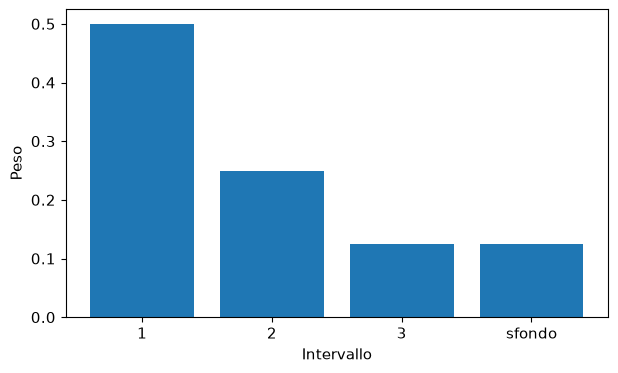

In [2]:
sigma=np.ones(3); delta=np.full(3,np.log(2.)); colors=np.eye(3); background=np.zeros(3)
alpha=1-np.exp(-sigma*delta)
T=np.r_[1.,np.cumprod(1-alpha)]
weights=T[:-1]*alpha; color=weights@colors+T[-1]*background
volume={'alpha':alpha,'trasmittanza':T,'pesi':weights,'residuo':T[-1],
        'somma_pesi_piu_residuo':weights.sum()+T[-1],'RGB':color}
assert np.isclose(weights.sum()+T[-1],1) and np.allclose(color,[.5,.25,.125])
print(volume); salva_json('volume.json',volume)
np.savetxt(output/'volume.csv',np.column_stack([sigma,delta,alpha,T[:-1],weights]),delimiter=',',header='sigma,delta,alpha,T,peso',comments='')
fig,ax=plt.subplots();ax.bar(['1','2','3','sfondo'],np.r_[weights,T[-1]]);ax.set(xlabel='Intervallo',ylabel='Peso');fig.savefig(output/'pesi.png',dpi=180,bbox_inches='tight');plt.show()


### Interpretazione

N15.A.1 — Derivare l’identità somma pesi più trasmittanza finale uguale a uno.

N15.A.2 — Perché normalizzare soltanto i tre pesi cambia il rendering?

## B — Covarianza e prospettiva

Usiamo una Gaussiana sull’asse ottico con covarianza diagonale e focali in pixel. La proiezione della covarianza è locale: non è il rasterizzatore completo né una stima di incertezza.

In [3]:
f=800.; covariance=np.diag([.02**2,.02**2,.04**2]); footprints=[]
for z in [2.,4.,8.]:
    J=np.array([[f/z,0.,0.],[0.,f/z,0.]])
    cov2=J@covariance@J.T
    footprints.append({'Z_m':z,'covarianza_pixel2':cov2,'deviazioni_pixel':np.sqrt(np.linalg.eigvalsh(cov2))})
assert np.allclose(footprints[1]['deviazioni_pixel'],[4,4])
print(footprints); salva_json('footprint.json',footprints)
np.savetxt(output/'footprint.csv',[[r['Z_m'],*r['deviazioni_pixel']] for r in footprints],delimiter=',',header='Z_m,std1_pixel,std2_pixel',comments='')


[{'Z_m': 2.0, 'covarianza_pixel2': array([[64.,  0.],
       [ 0., 64.]]), 'deviazioni_pixel': array([8., 8.])}, {'Z_m': 4.0, 'covarianza_pixel2': array([[16.,  0.],
       [ 0., 16.]]), 'deviazioni_pixel': array([4., 4.])}, {'Z_m': 8.0, 'covarianza_pixel2': array([[4., 0.],
       [0., 4.]]), 'deviazioni_pixel': array([2., 2.])}]


### Interpretazione

N15.B.1 — Spiegare le unità di J, della covarianza 3D e della covarianza 2D.

N15.B.2 — Perché la deviazione dimezza raddoppiando Z? Quale ipotesi limita questa conclusione?

## C — Backprojection e ambiguità di scala

La camera usa x a destra, y in basso e z in avanti. La trasformazione è mondo-camera. Il confronto di scala moltiplica sia i punti mondo sia la traslazione.

In [4]:
K=np.array([[500.,0.,320.],[0.,500.,240.],[0.,0.,1.]])
pixel=np.array([420.,290.,1.]); point_camera=2*np.linalg.solve(K,pixel)
angle=np.pi/2; R=np.array([[np.cos(angle),-np.sin(angle),0.],[np.sin(angle),np.cos(angle),0.],[0.,0.,1.]])
t=np.array([.1,-.2,.3]); X=np.array([[.4,.2,2.],[.2,-.3,3.],[-.5,.4,4.]])
def project(X,R,t,K):
    Xc=np.asarray(X)@R.T+t
    if np.any(Xc[:,2]<=0): raise ValueError('Punto non visibile davanti alla camera')
    h=Xc@K.T
    return h[:,:2]/h[:,2,None],Xc[:,2]
uv,z=project(X,R,t,K)
pixel_h=np.column_stack([uv,np.ones(len(uv))])
Xc_back=(np.linalg.solve(K,pixel_h.T).T)*z[:,None]
X_back=(Xc_back-t)@R
uv_scaled,_=project(2*X,R,2*t,K)
geometry={'punto_camera_da_pixel':point_camera,'errore_roundtrip_max':np.max(np.abs(X-X_back)),
          'errore_riproiezione_scala_max_pixel':np.max(np.abs(uv-uv_scaled)),
          'pixel':uv,'scala_m_per_unita':.20/.05}
assert np.allclose(point_camera,[.4,.2,2]) and np.allclose(X_back,X) and np.allclose(uv_scaled,uv)
print(geometry); salva_json('geometria.json',geometry)
np.savetxt(output/'riproiezione.csv',np.column_stack([uv,uv_scaled]),delimiter=',',header='u,v,u_scala2,v_scala2',comments='')


{'punto_camera_da_pixel': array([0.4, 0.2, 2. ]), 'errore_roundtrip_max': np.float64(2.7755575615628914e-16), 'errore_riproiezione_scala_max_pixel': np.float64(0.0), 'pixel': array([[298.26086957, 283.47826087],
       [380.60606061, 240.        ],
       [285.11627907, 158.60465116]]), 'scala_m_per_unita': 4.0}


### Interpretazione

N15.C.1 — Perché il roundtrip prova una coerenza interna ma non certifica la posa di una camera reale?

N15.C.2 — Quale misura esterna fissa la scala e quali errori locali possono rimanere?

## Conservare e interpretare gli output

Controllare i file nella cartella di output e scaricarli insieme al notebook se si usa un runtime temporaneo. JSON e CSV distinguono valori analitici assegnati, campioni sintetici e risultati dei calcoli. Le verifiche numeriche non stimano le prestazioni dei modelli reali. Per studiarli occorrono pesi, dati, licenze e un protocollo separato.

## Risorse primarie e implementazioni ufficiali

- [NeRF, progetto degli autori](https://www.matthewtancik.com/nerf)

- [3D Gaussian Splatting, codice degli autori](https://github.com/graphdeco-inria/gaussian-splatting)

- [VGGT, codice degli autori](https://github.com/facebookresearch/vggt)